In [1]:
print("hello world")

hello world


In [2]:
import pandas as pd 
tabela = pd.DataFrame(
    {"Nome": ["lira", "Fabricio"] , "idade" : [29,30]}
)
display(tabela)

,Nome,idade
0,lira,29
1,Fabricio,30


In [3]:
import ee
import eerepr
ee.Authenticate()
ee.Initialize(project='poetic-tesla-506814-e1')

In [4]:

print(ee.String('Hello from the Earth Engine servers!').getInfo())

Hello from the Earth Engine servers!


# ETAPA 1 : importação de Bibliotecas e inicialização do Earth Engine

In [5]:
import geemap
import ee
import eerepr

In [6]:
eerepr.initialize()

# inicializa um map object

In [7]:
m = geemap.Map()

# Etapa 2: Definir a Região de Interesse (Estado do Tocantins)

**Filtramos as fronteiras oficiais do IBGE para isolar apenas o Tocantins.**

In [8]:
tocantins = ee.FeatureCollection("IBGE/UF/V2025") \
    .filter(ee.Filter.eq("SIGLA_UF", "TO"))
tocantins

# Etapa 3: Carregar e Processar o Dataset Oficial de Queimadas
**- Usamos o conjunto de dados MCD64A1 Version 6.1 (MODIS Burned Area Monthly 500m).**
**- A banda BurnDate registra o dia do ano em que a queimada ocorreu.**   
**- Faremos o acumulado do 1º Semestre de 2025 (01/01/2025 a 30/06/2025) e do 1º Semestre de 2026 (01/01/2026 a 30/06/2026).**   
---
**qual foi o tipo de banda espectral utilizada?
**O dataset MCD64A1 retorna valores já classificados?
**MCD64A1 pode representar acurácia ?
**Qual é a escala de qualidade de pixel do dataset?
**qual foi o sample utilizado e por que?
**pode representar uma exemplo fiel ?
**Como criar a propria classificação utilizando um dataSet ?

In [9]:
# Coleção MODIS MCD64A1
queimadas_coll = ee.ImageCollection("MODIS/061/MCD64A1")

In [10]:
# --- 1º Semestre de 2025 ---
q_2025_sem1 = queimadas_coll \
    .filterDate('2025-01-01', '2025-06-30') \
    .select('BurnDate') \
    .max() \
    .gt(0) \
    .clip(tocantins)

# --- 1º Semestre de 2026 ---
q_2026_sem1 = queimadas_coll \
    .filterDate('2026-01-01', '2026-06-30') \
    .select('BurnDate') \
    .max() \
    .gt(0) \
    .clip(tocantins)

# Etapa 4: Criar Camadas de Visualização (Tile Layers)

Convertemos os dados binários de queimada em camadas prontas para o motor de mapa interativo do ipyleaflet.

In [11]:
# Parâmetros de visualização (máscara para exibir apenas pixels com queimada em vermelho)
vis_params_2025 = {'palette': ['ff0000'], 'min': 1, 'max': 1}
vis_params_2026 = {'palette': ['orange'], 'min': 1, 'max': 1}

# Aplicamos selfMask() para que áreas não queimadas fiquem transparentes
left_layer = geemap.ee_tile_layer(
    q_2025_sem1.selfMask(), 
    vis_params_2025, 
    name="Queimadas 1º Sem 2025"
)

right_layer = geemap.ee_tile_layer(
    q_2026_sem1.selfMask(), 
    vis_params_2026, 
    name="Queimadas 1º Sem 2026"
)

Etapa 5: Renderizar o Mapa Interativo com Slice (Split Map)

Criamos o mapa base centralizado no Tocantins e aplicamos o controle divisor deslizante (Split Control).

In [12]:
# Inicializa o mapa com o backend ipyleaflet
Map = geemap.Map()

# Centraliza o mapa na geometria do Tocantins com zoom 7
Map.centerObject(tocantins, 7)

# Adiciona a borda do estado do Tocantins
Map.addLayer(tocantins.style(**{'color': 'white', 'fillColor': '00000000', 'width': 2}), {}, "Limite TO")

# Aplica o Split Map (Lado Esquerdo: 2025 / Lado Direito: 2026)
Map.split_map(left_layer, right_layer)

# Exibe o mapa no Jupyter Notebook
Map

Map(center=[-10.13884920375508, -48.33010982744958], controls=(ZoomControl(options=['position', 'zoom_in_text'…

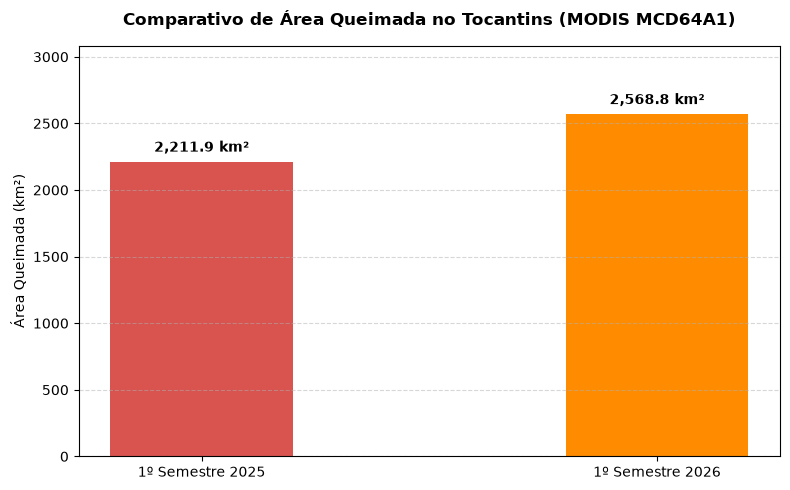

,Período,Área Queimada (km²),Área Queimada (ha)
0,1º Semestre 2025,2211.941764,221194.176447
1,1º Semestre 2026,2568.760783,256876.078329


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Função para extrair a área acumulada em km² via Earth Engine
def obter_area_km2(imagem_binaria, geometria):
    # Utiliza-se a função pixelArea() com o redutor ee.Reducer.sum()
    area_imagem = imagem_binaria.multiply(ee.Image.pixelArea().divide(1e6)) # iiso converte de m² para km²
    resultado = area_imagem.reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=geometria,
        scale=500,
        maxPixels=1e9
    )
    return resultado.get('BurnDate').getInfo()

# 2. Executa os cálculos para o Tocantins
area_2025 = obter_area_km2(q_2025_sem1, tocantins)
area_2026 = obter_area_km2(q_2026_sem1, tocantins)

# 3. Estruturação do DataFrame com Pandas
df_queimadas = pd.DataFrame({
    'Período': ['1º Semestre 2025', '1º Semestre 2026'],
    'Área Queimada (km²)': [area_2025, area_2026]
})

# Adiciona coluna em Hectares (1 km² = 100 ha)
df_queimadas['Área Queimada (ha)'] = df_queimadas['Área Queimada (km²)'] * 100

# 4. Plotagem do gráfico comparativo
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df_queimadas['Período'], 
    df_queimadas['Área Queimada (km²)'], 
    color=['#d9534f', '#ff8c00'], 
    width=0.4
)

# Estilização
ax.set_title('Comparativo de Área Queimada no Tocantins (MODIS MCD64A1)', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('Área Queimada (km²)', fontsize=10)
ax.set_ylim(0, max(df_queimadas['Área Queimada (km²)']) * 1.2) # Espaço superior para rótulos
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Adiciona rótulos de valor no topo de cada barra
for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        yval + (max(df_queimadas['Área Queimada (km²)']) * 0.02), 
        f'{yval:,.1f} km²', 
        ha='center', 
        va='bottom', 
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

# Exibe a tabela detalhada
df_queimadas